In [1]:
import sys
sys.path.append("/Experiments/riccardop02")

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

/Experiments/riccardop02/poseJepa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
MODEL_NAME = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 6936.44it/s]


facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [ ]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features(img: Image.Image, layers=[-1], token="cls", normalize=True):
    """
    Estrae e concatena le feature dei layer richiesti.
      layers   : lista di indici, es. [2, 3, 11]
      token    : "cls"   -> usa il CLS token di ogni layer        -> (len(layers)*768,)
                 "patch" -> media dei patch token di ogni layer   -> (len(layers)*768,)
      normalize: L2 su ogni blocco-layer prima di concatenare (consigliato)
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states   # 13 layer (ViT-B)

    parts = []
    for L in layers:
        h = hs[L][0]                          # (n_token, 768)
        if token == "cls":
            v = h[0]                          # (768,) token globale
        elif token == "patch":
            v = h[1:].mean(dim=0)             # (768,) media dei 256 patch token
        else:
            raise ValueError(token)
        if normalize:
            v = F.normalize(v, dim=-1)
        parts.append(v)

    return torch.cat(parts, dim=-1)           # (len(layers)*768,)

# prova
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features(dummy, layers=[-1], token="cls")
print("Dimension Descriptor:", emb.shape)            

descrittore: torch.Size([768])


In [8]:
@torch.no_grad()
def compare(img1, img2, layers=[-1], token="cls"):
    e1 = extract_features(img1, layers=layers, token=token)
    e2 = extract_features(img2, layers=layers, token=token)

    cos_sim  = F.cosine_similarity(e1, e2, dim=0).item()
    cos_dist = 1.0 - cos_sim
    l2       = torch.norm(e1 - e2).item()
    l1       = torch.abs(e1 - e2).sum().item()      # la distanza "di JEPA"
    return {"cos_sim": cos_sim, "cos_dist": cos_dist, "l2": l2, "l1": l1}

# --- prova: posa vicina vs posa lontana ---
img0     = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+115_ry-041_rz+045_tx+000_ty+000_tz-290.png").convert("RGB")
img_near = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+108_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_nearer = Image.open(RENDERS / "icbin" / "obj_000001_pose0004_rx+144_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_far  = Image.open(RENDERS / "icbin" / "obj_000001_pose0000_rx+000_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")

dn = compare(img0, img_near)
df = compare(img0, img_far)
dnn = compare(img0, img_nearer)
print(f"vicina  -> cos_dist {dn['cos_dist']:.4f} | L2 {dn['l2']:.4f} | L1 {dn['l1']:.4f}")
print(f"vicinissima  -> cos_dist {dnn['cos_dist']:.4f} | L2 {dnn['l2']:.4f} | L1 {dnn['l1']:.4f}")
print(f"lontana -> cos_dist {df['cos_dist']:.4f} | L2 {df['l2']:.4f} | L1 {df['l1']:.4f}")

vicina  -> cos_dist 0.4351 | L2 0.9328 | L1 19.8845
vicinissima  -> cos_dist 0.5343 | L2 1.0338 | L1 22.0313
lontana -> cos_dist 0.6499 | L2 1.1401 | L1 24.5918


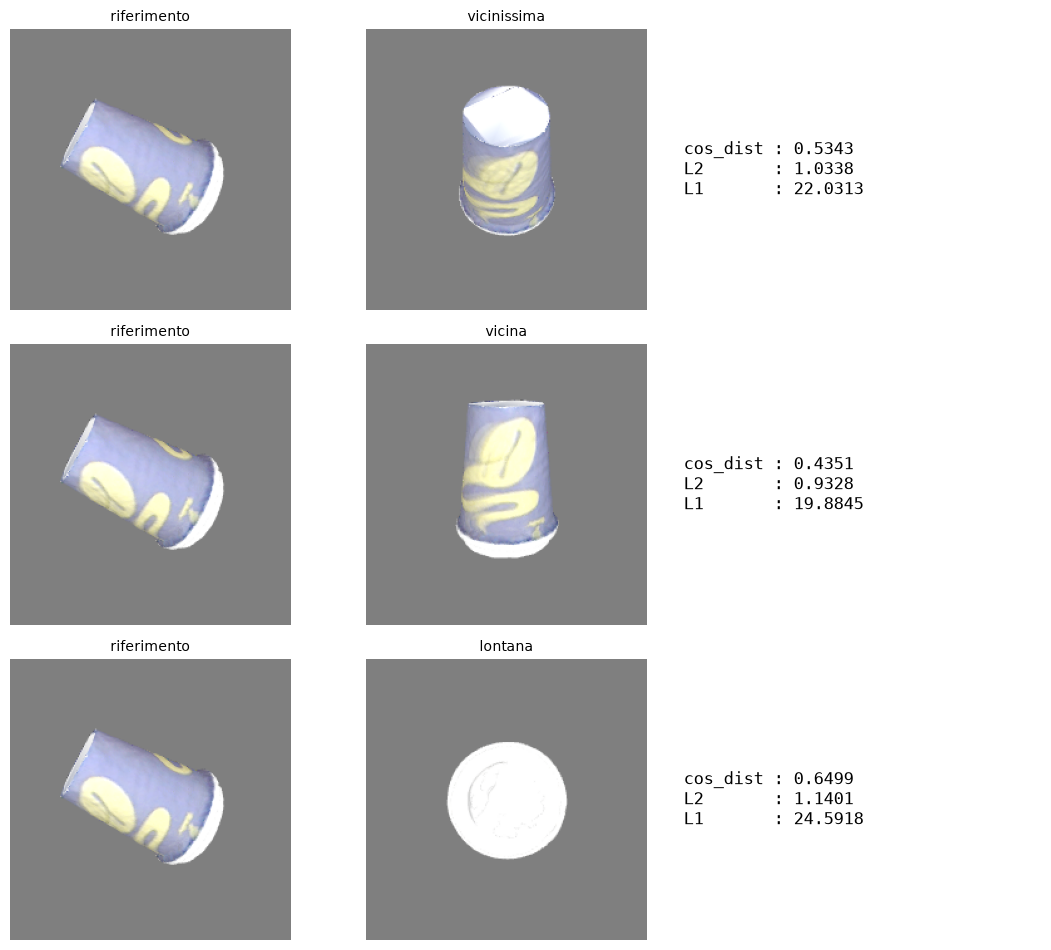

In [9]:
def plot_comparisons(ref_img, others, labels, layers=[-1], token="cls"):
    """
    Per ogni confronto mostra: [ref | altra | metriche].
      ref_img : immagine di riferimento (PIL)
      others  : lista di immagini PIL da confrontare con ref
      labels  : lista di etichette (es. ["vicinissima", "vicina", "lontana"])
    """
    n = len(others)
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.2 * n))
    if n == 1:
        axes = axes[None, :]          # uniforma la forma quando c'è un solo confronto

    for row, (img, lab) in enumerate(zip(others, labels)):
        d = compare(ref_img, img, layers=layers, token=token)

        axes[row, 0].imshow(ref_img)
        axes[row, 0].set_title("riferimento", fontsize=10)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img)
        axes[row, 1].set_title(lab, fontsize=10)
        axes[row, 1].axis("off")

        txt = (f"cos_dist : {d['cos_dist']:.4f}\n"
               f"L2       : {d['l2']:.4f}\n"
               f"L1       : {d['l1']:.4f}")
        axes[row, 2].text(0.0, 0.5, txt, fontsize=12, family="monospace",
                          va="center", ha="left")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()


# --- uso: ordina dal più vicino al più lontano ---
plot_comparisons(
    ref_img = img0,
    others  = [img_nearer, img_near, img_far],
    labels  = ["vicinissima", "vicina", "lontana"],
)